# 03 — Baseline models

Establish trustworthy cross-validation baselines before comparing more complex classifiers. Poisonous mushrooms are the positive class (`1`); a false negative means a poisonous mushroom was predicted edible.

This notebook uses only the raw training split. It does not load the held-out test set, tune hyperparameters, or save a production model. These educational results are not reliable evidence that any real mushroom is safe to eat.

## 2. Imports and configuration

Locate the repository independent of the notebook's launch directory and reuse the shared preprocessing factory from the data-preparation workflow.

In [27]:
# Standard-library helpers for paths, metadata, and importing the shared project code.
from pathlib import Path
import json
import sys

# Libraries for result tables, reproducible plots, and baseline estimators/metrics.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_curve,
)
# Cross-validation tools create identical folds and out-of-fold predictions for review.
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline

# Fix the fold layout and positive label convention for reproducible results.
RANDOM_STATE = 42
N_SPLITS = 5
TARGET = "class"
TARGET_MAPPING = {"e": 0, "p": 1}

# Locate the repository root from either a root or nested notebook working directory.
PROJECT_ROOT = next(
    (
        candidate for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "mushroom" / "preprocessing.py").is_file()
        and (candidate / "requirements.txt").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root containing mushroom/preprocessing.py.")
# Make project modules importable without changing the notebook's working directory.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Reuse the same fold-compatible preprocessing implementation used in later notebooks.
from mushroom.preprocessing import build_preprocessor

# Keep results and figures in the established project artifact folders.
DATA_DIR = PROJECT_ROOT / "mushroom" / "data"
FIGURE_DIR = DATA_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 3. Load and validate training data

Read only raw training predictors, encoded training labels, and optional preparation metadata. Pre-transformed data and all test files are deliberately excluded so the preprocessing can be refit inside each fold.

In [28]:
# Load only the saved training features and labels; do not inspect the held-out test set.
X_PATH = DATA_DIR / "mushroom_X_train_raw.parquet"
Y_PATH = DATA_DIR / "mushroom_y_train.parquet"
METADATA_PATH = DATA_DIR / "mushroom_preprocessing_metadata.json"
# Stop with an actionable message if data preparation has not produced the needed files.
for required_path in (X_PATH, Y_PATH):
    if not required_path.is_file():
        raise FileNotFoundError(
            f"Required training artifact not found: {required_path}. "
            "Run 02_data_preparation.ipynb first."
        )

# Read features and labels separately, then check their alignment before evaluation.
X_train = pd.read_parquet(X_PATH)
y_frame = pd.read_parquet(Y_PATH)
if TARGET not in y_frame.columns:
    raise ValueError(f"Expected target column {TARGET!r} in {Y_PATH}.")
y_train = y_frame[TARGET].rename(TARGET)
# Metadata is optional, but when present it verifies the expected mapping and feature schema.
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8")) if METADATA_PATH.is_file() else None

# Validate that there is data, that X and y align, and that both expected labels are present.
if X_train.empty or y_train.empty:
    raise ValueError("Training predictors or labels are empty.")
if len(X_train) != len(y_train):
    raise ValueError(f"Training row counts differ: X={len(X_train)}, y={len(y_train)}.")
if not X_train.index.equals(y_train.index):
    raise ValueError("Training predictor and target row indices/order do not match.")
if X_train.columns.has_duplicates:
    raise ValueError("Training feature columns contain duplicate names.")
if y_train.isna().any() or not set(y_train.unique()).issubset({0, 1}):
    raise ValueError("Target labels must be non-missing integers 0 (edible) or 1 (poisonous).")
if set(y_train.unique()) != {0, 1}:
    raise ValueError("Both encoded target classes 0 and 1 must be present in training data.")

# Prefer recorded feature types; only infer them when metadata is unavailable.
if metadata is not None:
    if metadata.get("target_mapping") != TARGET_MAPPING:
        raise ValueError(f"Target mapping does not match preparation metadata: {metadata.get('target_mapping')}.")
    expected_features = metadata.get("raw_feature_order")
    if expected_features is not None and X_train.columns.tolist() != expected_features:
        raise ValueError("Training feature columns/order differ from preparation metadata.")
    numeric_cols = metadata.get("numerical_features")
    categorical_cols = metadata.get("categorical_features")
else:
    numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
    categorical_cols = [column for column in X_train.columns if column not in numeric_cols]

# Ensure every column belongs to exactly one metadata type group and declared types match.
if numeric_cols is None or categorical_cols is None:
    raise ValueError("Preparation metadata is missing numerical/categorical feature names.")
if set(numeric_cols).union(categorical_cols) != set(X_train.columns):
    raise ValueError("Numerical/categorical metadata does not match the raw training feature schema.")
if set(numeric_cols).intersection(categorical_cols):
    raise ValueError("Numerical and categorical feature lists overlap.")
for column in numeric_cols:
    if not pd.api.types.is_numeric_dtype(X_train[column]):
        raise TypeError(f"Expected numeric feature {column!r}, got {X_train[column].dtype}.")
for column in categorical_cols:
    if pd.api.types.is_numeric_dtype(X_train[column]):
        raise TypeError(f"Expected categorical feature {column!r}, got {X_train[column].dtype}.")

# Show verified input dimensions, positive class meaning, and class balance before modeling.
print(f"Training feature shape: {X_train.shape}; target shape: {y_train.shape}")
print("Target mapping: 0=edible, 1=poisonous (positive class)")
print("Training target distribution:")
display(y_train.value_counts().sort_index().rename(index={0: "Edible (0)", 1: "Poisonous (1)"}).to_frame("count"))
print(f"Feature types: {len(numeric_cols)} numeric, {len(categorical_cols)} categorical")

Training feature shape: (4000, 10); target shape: (4000,)
Target mapping: 0=edible, 1=poisonous (positive class)
Training target distribution:


,count
class,
Edible (0),2486
Poisonous (1),1514


Feature types: 3 numeric, 7 categorical


## 4. Define preprocessing pipeline

Every estimator is wrapped in a pipeline containing a fresh preprocessor. `cross_validate` clones and fits each pipeline separately on each fold's training rows, so medians, scaling statistics, missing indicators, and one-hot vocabularies never see that fold's validation rows.

In [29]:
# Build a fresh preprocessor for each pipeline. During CV, sklearn clones the complete
# pipeline, so imputation and encoding are learned only from that fold's training rows.
def make_model_pipeline(classifier):
    """Create a classifier pipeline with a fresh, unfitted fold-local preprocessor."""
    return Pipeline(
        steps=[
            ("preprocessor", build_preprocessor(numeric_cols, categorical_cols)),
            ("model", classifier),
        ]
    )

## 5. Define baseline classifiers

The most-frequent dummy predicts the majority class every time; on this training data that is edible, so its poisonous recall is zero. The stratified dummy randomly samples predictions according to class frequencies. Logistic Regression is the first baseline that learns feature relationships; it uses default regularization and no tuning.

In [30]:
# Dummy baselines ignore the predictors and establish simple reference performance.
# Logistic Regression is the first model that learns a decision rule from features.
models = {
    "Dummy — Most Frequent": DummyClassifier(strategy="most_frequent"),
    "Dummy — Stratified": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
}
# Give every estimator the same preprocessing recipe while keeping each fitted transformer separate.
pipelines = {name: make_model_pipeline(classifier) for name, classifier in models.items()}
print("Models:", list(pipelines))

Models: ['Dummy — Most Frequent', 'Dummy — Stratified', 'Logistic Regression']


## 6. Configure stratified cross-validation

Use identical shuffled stratified folds for all three baselines. The test partition is not loaded or used. The pipeline ensures that preprocessing is fitted only within each fold's training portion.

In [31]:
# Stratification keeps class proportions similar in every fold. Shuffling and the fixed
# seed make fold membership reproducible for comparisons with subsequent models.
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


## 7. Define evaluation metrics

Poisonous precision, recall, and F1 explicitly treat label `1` as positive. `zero_division=0` makes precision well-defined for a model that predicts no poisonous mushrooms. Accuracy alone can be misleading with approximately 62% edible and 38% poisonous data; balanced accuracy, precision, and confusion matrices add important context.

In [32]:
# Precision, recall, and F1 explicitly treat poisonous label 1 as the positive class.
# zero_division=0 defines precision if an estimator predicts no poisonous examples.
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "poisonous_precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "poisonous_recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "poisonous_f1": make_scorer(f1_score, pos_label=1, zero_division=0),
    "roc_auc": "roc_auc",
}
# Reuse this ordered metric list when generating tables and saved metadata.
METRIC_KEYS = list(scoring)

## 8. Train and evaluate baseline models

Here, “train” refers only to repeated fold-specific fitting inside cross-validation. `error_score="raise"` ensures failures are visible. We retain the mean and standard deviation across all five validation folds.

In [33]:
# Fit and validate each complete pipeline on the same five folds. Because the preprocessor
# is inside the pipeline, validation rows cannot affect learned imputation or encoding.
cv_results = {}
for name, pipeline in pipelines.items():
    cv_results[name] = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        error_score="raise",
        # Report validation performance only; training scores are not generalization evidence.
        return_train_score=False,
        # Keep the small baseline run's resource usage predictable.
        n_jobs=1,
    )
print(f"Completed {N_SPLITS}-fold cross-validation for {len(cv_results)} baseline models.")

Completed 5-fold cross-validation for 3 baseline models.


## 9. Compare cross-validation results

The table reports mean scores rounded to four decimals while preserving each metric's fold standard deviation. Rank by poisonous recall for review, not as an automatic winner selection; precision and balanced accuracy show the cost and balance of those detections.

In [34]:
# Aggregate the five validation-fold scores into a compact mean and variability table.
result_rows = []
for name, result in cv_results.items():
    row = {"Model": name}
    for metric in METRIC_KEYS:
        scores = result[f"test_{metric}"]
        # Use the sample standard deviation to show how much results vary by fold.
        row[f"{metric}_mean"] = float(np.mean(scores))
        row[f"{metric}_std"] = float(np.std(scores, ddof=1))
    result_rows.append(row)

results_df = pd.DataFrame(result_rows).set_index("Model")
# Sort by poisonous recall to foreground detection sensitivity, but compare the other
# metrics too; recall alone can reward an estimator that over-predicts poisonous.
ranked_results = results_df.sort_values("poisonous_recall_mean", ascending=False)
display(ranked_results.round(4))

,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,poisonous_precision_mean,poisonous_precision_std,poisonous_recall_mean,poisonous_recall_std,poisonous_f1_mean,poisonous_f1_std,roc_auc_mean,roc_auc_std
Model,,,,,,,,,,,,
Dummy — Stratified,0.5325,0.0096,0.5029,0.0102,0.3821,0.0130,0.3811,0.0127,0.3816,0.0128,0.5029,0.0102
Logistic Regression,0.6960,0.0121,0.6279,0.0144,0.6991,0.0388,0.3474,0.0324,0.4633,0.0293,0.6882,0.0216
Dummy — Most Frequent,0.6215,0.0006,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000


## 10. Visualize model performance

This grouped bar chart compares poisonous recall, poisonous precision, poisonous F1, and balanced accuracy. The metrics are on the same 0–1 scale; the chart complements, rather than replaces, the full table and standard deviations.

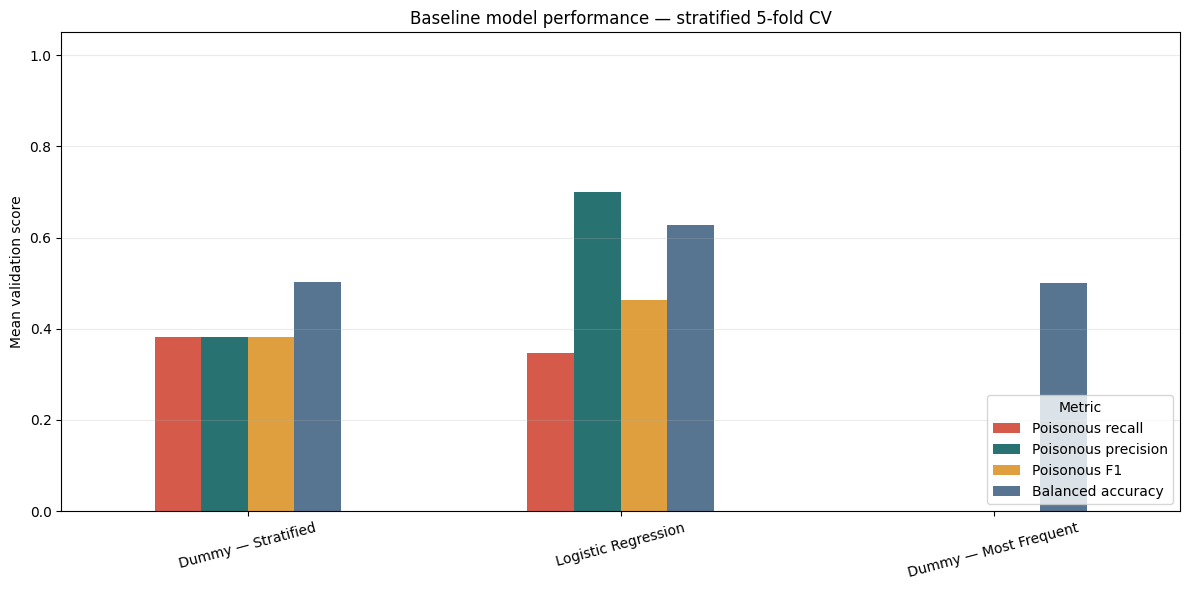

In [35]:
# Plot complementary validation metrics rather than relying on accuracy alone.
# Recall measures poisonous detections; precision measures correctness of those alerts;
# F1 combines the two, and balanced accuracy gives both classes equal weight.
plot_metrics = [
    ("poisonous_recall_mean", "Poisonous recall", "#d65a4a"),
    ("poisonous_precision_mean", "Poisonous precision", "#287271"),
    ("poisonous_f1_mean", "Poisonous F1", "#e09f3e"),
    ("balanced_accuracy_mean", "Balanced accuracy", "#577590"),
]
# Use the same ranking shown in the table so model ordering remains consistent.
ax = ranked_results[[key for key, _, _ in plot_metrics]].rename(
    columns={key: label for key, label, _ in plot_metrics}
).plot(kind="bar", figsize=(12, 6), color=[color for _, _, color in plot_metrics])
ax.set_title("Baseline model performance — stratified 5-fold CV")
ax.set_ylabel("Mean validation score")
ax.set_xlabel("")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=15)
ax.legend(title="Metric", loc="lower right")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
comparison_figure = ax.figure
# Save before displaying so the file is written even after the figure is closed below.
comparison_figure.savefig(FIGURE_DIR / "mushroom_baseline_comparison.png", dpi=160, bbox_inches="tight")
# Render once explicitly, then close to prevent the notebook's end-of-cell hook from repeating it.
plt.show()
plt.close(comparison_figure)

## 11. Analyze out-of-fold confusion matrices

Out-of-fold predictions are generated by fitting each model on four folds and predicting the held-out fold. In the matrices, rows are true classes and columns are predicted classes. A false negative (`FN`) is truly poisonous (`1`) but predicted edible (`0`).

Dummy — Most Frequent: TN=2486, FP=0, FN=1514, TP=0
Logistic Regression: TN=2258, FP=228, FN=988, TP=526


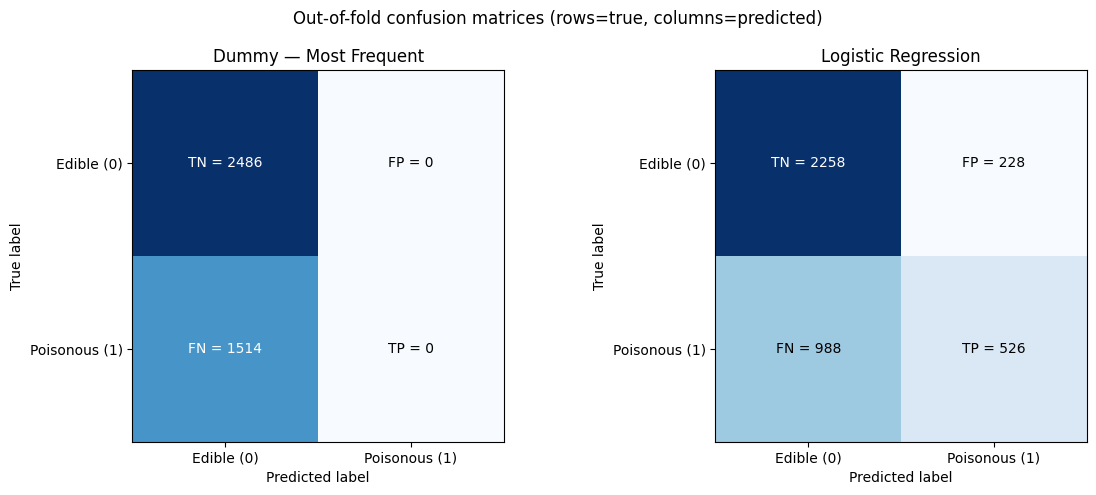

In [36]:
# Generate one prediction per training observation from the fold where that row was held out.
# These out-of-fold (OOF) predictions make the confusion matrix a CV result, not an in-sample one.
confusion_model_names = ["Dummy — Most Frequent", "Logistic Regression"]
oof_predictions = {
    name: cross_val_predict(pipelines[name], X_train, y_train, cv=cv, method="predict", n_jobs=1)
    for name in confusion_model_names
}
# Keep class order explicit: rows are actual labels and columns are predicted labels.
confusion_matrices = {
    name: confusion_matrix(y_train, predictions, labels=[0, 1])
    for name, predictions in oof_predictions.items()
}

fig, axes = plt.subplots(1, len(confusion_model_names), figsize=(12, 5))
# In this layout [1, 0] is a poisonous mushroom incorrectly called edible (false negative).
role_labels = np.array([["TN", "FP"], ["FN", "TP"]])
for ax, name in zip(axes, confusion_model_names):
    matrix = confusion_matrices[name]
    display_obj = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Edible (0)", "Poisonous (1)"],
    )
    display_obj.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
    for (row, col), text in zip(np.ndindex(matrix.shape), ax.texts):
        text.set_text(f"{role_labels[row, col]} = {matrix[row, col]}")
        text.set_fontsize(10)
        text.set_color("white" if matrix[row, col] > matrix.max() / 2 else "black")
    tn, fp, fn, tp = matrix.ravel()
    print(f"{name}: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
fig.suptitle("Out-of-fold confusion matrices (rows=true, columns=predicted)")
fig.tight_layout()
# Save before displaying so the artifact remains available after the figure is closed.
fig.savefig(FIGURE_DIR / "mushroom_baseline_confusion_matrices.png", dpi=160, bbox_inches="tight")
# Render once explicitly, then close to prevent duplicate inline output.
plt.show()
plt.close(fig)

## 12. Plot ROC curves

ROC-AUC measures how well predicted scores rank poisonous examples above edible ones across decision thresholds. Probabilities are generated out of fold using the same stratified folds; the diagonal is random ranking.

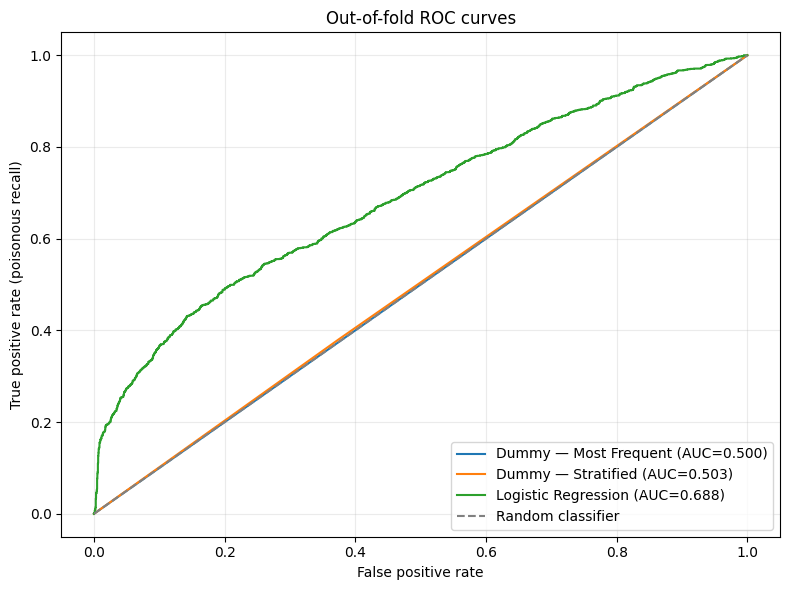

In [37]:
# Plot OOF probability scores so each point's score comes from a model that did not
# train on that observation. ROC curves compare ranking across decision thresholds.
fig, ax = plt.subplots(figsize=(8, 6))
oof_probabilities = {}
for name, pipeline in pipelines.items():
    # cross_val_predict returns a probability row for every example using its held-out fold model.
    probabilities = cross_val_predict(
        pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1
    )
    # Select the probability column for label 1 explicitly rather than assuming its position.
    fitted_classes = np.unique(y_train)
    positive_column = int(np.flatnonzero(fitted_classes == 1)[0])
    positive_scores = probabilities[:, positive_column]
    oof_probabilities[name] = positive_scores
    false_positive_rate, true_positive_rate, _ = roc_curve(y_train, positive_scores, pos_label=1)
    # Compute and display area under this OOF ROC curve for each candidate.
    curve_auc = auc(false_positive_rate, true_positive_rate)
    ax.plot(false_positive_rate, true_positive_rate, label=f"{name} (AUC={curve_auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random classifier")
ax.set_title("Out-of-fold ROC curves")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (poisonous recall)")
ax.legend(loc="lower right")
ax.grid(alpha=0.25)
fig.tight_layout()
# Save the CV ROC figure before display/cleanup; this is not held-out test performance.
fig.savefig(FIGURE_DIR / "mushroom_baseline_roc_curves.png", dpi=160, bbox_inches="tight")
# Render once explicitly, then close to prevent duplicate inline output.
plt.show()
plt.close(fig)

## Baseline Results — Interpretation

The following code derives the comparison statements from the observed cross-validation and out-of-fold results rather than assuming outcomes in advance. Poisonous recall matters because false negatives are poisonous mushrooms incorrectly labeled edible. Recall alone is not enough: predicting every mushroom poisonous could yield perfect recall but poor precision and overall balance. Consider balanced accuracy, precision, F1, and the confusion matrix together. Dummy models do not learn feature relationships; Logistic Regression is linear and may miss nonlinear interactions, which motivates later model comparisons.

In [38]:
# Find the leaders on two individual metrics for context, not automatic model selection.
accuracy_winner = results_df["accuracy_mean"].idxmax()
recall_winner = results_df["poisonous_recall_mean"].idxmax()
logistic_metrics = results_df.loc["Logistic Regression"]
# Matrix position [1, 0] counts poisonous examples predicted edible (false negatives).
logistic_fn = int(confusion_matrices["Logistic Regression"][1, 0])
most_frequent_fn = int(confusion_matrices["Dummy — Most Frequent"][1, 0])
print(f"Highest mean accuracy: {accuracy_winner} ({results_df.loc[accuracy_winner, 'accuracy_mean']:.4f}).")
print(f"Highest mean poisonous recall: {recall_winner} ({results_df.loc[recall_winner, 'poisonous_recall_mean']:.4f}).")
# A safety-oriented interpretation checks recall and false negatives alongside precision,
# F1, balanced accuracy, and ROC-AUC to understand the trade-offs.
print(
    "Logistic Regression: "
    f"accuracy={logistic_metrics['accuracy_mean']:.4f}, "
    f"balanced accuracy={logistic_metrics['balanced_accuracy_mean']:.4f}, "
    f"poisonous precision={logistic_metrics['poisonous_precision_mean']:.4f}, "
    f"poisonous recall={logistic_metrics['poisonous_recall_mean']:.4f}, "
    f"poisonous F1={logistic_metrics['poisonous_f1_mean']:.4f}, "
    f"ROC-AUC={logistic_metrics['roc_auc_mean']:.4f}."
)
print(f"Out-of-fold poisonous false negatives: Logistic Regression={logistic_fn}; Most Frequent dummy={most_frequent_fn}.")
print(
    "Interpret the recall/precision trade-off alongside balanced accuracy and false positives: "
    "a more sensitive model can catch more poisonous cases while also flagging more edible cases."
)
print(
    "Limitations: dummy classifiers ignore the predictors, and Logistic Regression assumes a "
    "linear decision boundary after preprocessing. Nonlinear models and feature interactions "
    "may improve results; later notebooks should compare them using the same training folds."
)

Highest mean accuracy: Logistic Regression (0.6960).
Highest mean poisonous recall: Dummy — Stratified (0.3811).
Logistic Regression: accuracy=0.6960, balanced accuracy=0.6279, poisonous precision=0.6991, poisonous recall=0.3474, poisonous F1=0.4633, ROC-AUC=0.6882.
Out-of-fold poisonous false negatives: Logistic Regression=988; Most Frequent dummy=1514.
Interpret the recall/precision trade-off alongside balanced accuracy and false positives: a more sensitive model can catch more poisonous cases while also flagging more edible cases.
Limitations: dummy classifiers ignore the predictors, and Logistic Regression assumes a linear decision boundary after preprocessing. Nonlinear models and feature interactions may improve results; later notebooks should compare them using the same training folds.


## 14. Save baseline results

Save means and standard deviations for each metric, plus a compact run summary and presentation figures. No test predictions or final model are saved.

In [39]:
# Save per-model CV means and standard deviations as a reusable results table.
results_path = DATA_DIR / "mushroom_baseline_results.csv"
results_df.reset_index().to_csv(results_path, index=False)
# Store the experiment setup with its outputs so later notebooks can assess comparability.
summary = {
    "models_evaluated": list(pipelines),
    "cross_validation": {
        "strategy": "StratifiedKFold",
        "n_splits": N_SPLITS,
        "shuffle": True,
        "random_state": RANDOM_STATE,
    },
    "target": TARGET,
    "target_mapping": TARGET_MAPPING,
    "positive_class": 1,
    "n_training_rows": int(len(X_train)),
    "n_training_features": int(X_train.shape[1]),
    "metrics": {
        model_name: {
            metric: {
                "mean": float(results_df.loc[model_name, f"{metric}_mean"]),
                "std": float(results_df.loc[model_name, f"{metric}_std"]),
            }
            for metric in METRIC_KEYS
        }
        for model_name in results_df.index
    },
}
# Write a readable summary; no fitted production model is created in this baseline notebook.
summary_path = DATA_DIR / "mushroom_baseline_summary.json"
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")
print(f"Saved cross-validation results: {results_path}")
print(f"Saved run summary: {summary_path}")
print(f"Saved figures in: {FIGURE_DIR}")

Saved cross-validation results: /Users/hamidiqbal/ThomasMore/deep learning/AWS/cloud_AI_challenge/cloud-ai-avenue-5/mushroom/data/mushroom_baseline_results.csv
Saved run summary: /Users/hamidiqbal/ThomasMore/deep learning/AWS/cloud_AI_challenge/cloud-ai-avenue-5/mushroom/data/mushroom_baseline_summary.json
Saved figures in: /Users/hamidiqbal/ThomasMore/deep learning/AWS/cloud_AI_challenge/cloud-ai-avenue-5/mushroom/data/figures
